# 2 · Estudo de caso Gama — comparação determinística

A Empresa Gama avalia quatro projetos **independentes** mas só pode implantar **dois**. IR = 20%; os acionistas
exigem **18% a.a.** A área técnica deve (i) avaliar por todos os métodos, (ii) indicar os dois melhores projetos e
(iii) o melhor projeto caso só um seja implantado.

| Projeto | Descrição | Investimento | Vida |
|---|---|---|---|
| P1 | Máquinas e equipamentos: +12.500 un./ano a $12, custo variável $5,80, sem custo fixo | $200.000 | 5 anos |
| P2 | Acoplamento de equipamento: receitas marginais decrescentes; CPV 60%, adm. 10%, vendas 9%; despesas gerais | $200.000 | 5 anos |
| P3 | Nova unidade: 60.000 un. crescendo 10% a.a. por 5 anos a $6; CPV e despesas em % da receita; depreciação $30.000/ano; VR $42.000 | $225.000 | 7 anos |
| P4 | Substituição de equipamentos: 30.000 un. (−2%, −2%, −3%), preço $20 (−5% no ano 4, −4% no ano 6); custo fixo $200.000; variável $9; VR por perpetuidade | $300.000 | 6 anos |

Este notebook faz a comparação **determinística** (caso-base). Os notebooks 3 e 4 acrescentam cenários e
simulação de Monte Carlo para comparar os riscos — algo que o enunciado não pede, mas que o board vai perguntar.

In [1]:
import numpy as np
import pandas as pd

from greenseer import *
from greenseer import viz

viz.configurar_notebook()
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

K = 0.18   # TMA: remuneração exigida pelos acionistas
IR = 0.20  # alíquota de IR
SAIDA = "../outputs/02"  # pasta para os gráficos exportados (HTML interativo + PNG)

## 1. Modelagem dos projetos

Cada projeto é descrito pelas suas premissas. As *especificações de série* (`Produto`, `Crescimento`,
`Variacoes`, `Percentual`…) permitem escrever o enunciado quase literalmente.

In [2]:
p1 = Projeto(
    "P1", vida_util=5, investimento=200_000,
    receitas=Produto(12_500, 12.0),                      # unidades × preço
    custos={"Custo variável": Produto(12_500, 5.80)},    # sem custo fixo adicional
    aliquota_ir=IR,                                      # depreciação linear em 5 anos, VR nulo (padrões)
)
estilizar_demonstrativo(p1.demonstrativo(), "P1 — aquisição de máquinas e equipamentos")

ano,0,1,2,3,4,5
P1,,,,,,
Receitas,–,$ 150.000,$ 150.000,$ 150.000,$ 150.000,$ 150.000
(−) Custos e despesas,–,$ 72.500,$ 72.500,$ 72.500,$ 72.500,$ 72.500
(=) EBITDA,–,$ 77.500,$ 77.500,$ 77.500,$ 77.500,$ 77.500
(−) Depreciação,–,$ 40.000,$ 40.000,$ 40.000,$ 40.000,$ 40.000
(=) Lucro operacional (EBIT),–,$ 37.500,$ 37.500,$ 37.500,$ 37.500,$ 37.500
(−) IR,–,$ 7.500,$ 7.500,$ 7.500,$ 7.500,$ 7.500
(=) NOPAT,–,$ 30.000,$ 30.000,$ 30.000,$ 30.000,$ 30.000
(+) Depreciação,–,$ 40.000,$ 40.000,$ 40.000,$ 40.000,$ 40.000
(=) Fluxo de caixa operacional,–,$ 70.000,$ 70.000,$ 70.000,$ 70.000,$ 70.000


In [3]:
p2 = Projeto(
    "P2", vida_util=5, investimento=200_000,
    receitas=[570_000, 550_000, 510_000, 423_000, 423_000],
    custos={
        "CPV (60%)": Percentual(0.60),
        "Despesas administrativas (10%)": Percentual(0.10),
        "Despesas de vendas (9%)": Percentual(0.09),
        "Despesas gerais": [17_200, 19_250, 23_350, 36_330, 36_330],
    },
    aliquota_ir=IR,
)
estilizar_demonstrativo(p2.demonstrativo(), "P2 — acoplamento de novo equipamento")

ano,0,1,2,3,4,5
P2,,,,,,
Receitas,–,$ 570.000,$ 550.000,$ 510.000,$ 423.000,$ 423.000
Custo · CPV (60%),–,$ 342.000,$ 330.000,$ 306.000,$ 253.800,$ 253.800
Custo · Despesas administrativas (10%),–,$ 57.000,$ 55.000,$ 51.000,$ 42.300,$ 42.300
Custo · Despesas de vendas (9%),–,$ 51.300,$ 49.500,$ 45.900,$ 38.070,$ 38.070
Custo · Despesas gerais,–,$ 17.200,$ 19.250,$ 23.350,$ 36.330,$ 36.330
(−) Custos e despesas,–,$ 467.500,$ 453.750,$ 426.250,$ 370.500,$ 370.500
(=) EBITDA,–,$ 102.500,$ 96.250,$ 83.750,$ 52.500,$ 52.500
(−) Depreciação,–,$ 40.000,$ 40.000,$ 40.000,$ 40.000,$ 40.000
(=) Lucro operacional (EBIT),–,$ 62.500,$ 56.250,$ 43.750,$ 12.500,$ 12.500


In [4]:
p3 = Projeto(
    "P3", vida_util=7, investimento=225_000,
    receitas=Produto(Crescimento(60_000, taxa=0.10, periodos=5), 6.0),   # cresce do ano 2 ao 6, estável no 7
    custos={
        "CPV": Percentual([0.67, 0.63, 0.63, 0.61, 0.60, 0.58, 0.58]),
        "Despesas operacionais": Percentual([0.25, 0.23, 0.23, 0.23, 0.21, 0.17, 0.17]),
    },
    depreciacao=Depreciacao.explicita(30_000),            # informada no enunciado (≠ investimento ÷ vida)
    valor_residual=ValorResidual.mercado(42_000),         # ganho sobre o valor contábil ($15.000) tributado a 20%
    aliquota_ir=IR,
)
estilizar_demonstrativo(p3.demonstrativo(), "P3 — nova unidade operacional")

ano,0,1,2,3,4,5,6,7
P3,,,,,,,,
Receitas,–,$ 360.000,$ 396.000,$ 435.600,$ 479.160,$ 527.076,$ 579.784,$ 579.784
Custo · CPV,–,$ 241.200,$ 249.480,$ 274.428,$ 292.288,$ 316.246,$ 336.274,$ 336.274
Custo · Despesas operacionais,–,$ 90.000,$ 91.080,$ 100.188,$ 110.207,$ 110.686,$ 98.563,$ 98.563
(−) Custos e despesas,–,$ 331.200,$ 340.560,$ 374.616,$ 402.494,$ 426.932,$ 434.838,$ 434.838
(=) EBITDA,–,$ 28.800,$ 55.440,$ 60.984,$ 76.666,$ 100.144,$ 144.946,$ 144.946
(−) Depreciação,–,$ 30.000,$ 30.000,$ 30.000,$ 30.000,$ 30.000,$ 30.000,$ 30.000
(=) Lucro operacional (EBIT),–,($ 1.200),$ 25.440,$ 30.984,$ 46.666,$ 70.144,$ 114.946,$ 114.946
(−) IR,–,($ 240),$ 5.088,$ 6.197,$ 9.333,$ 14.029,$ 22.989,$ 22.989
(=) NOPAT,–,($ 960),$ 20.352,$ 24.787,$ 37.332,$ 56.116,$ 91.957,$ 91.957


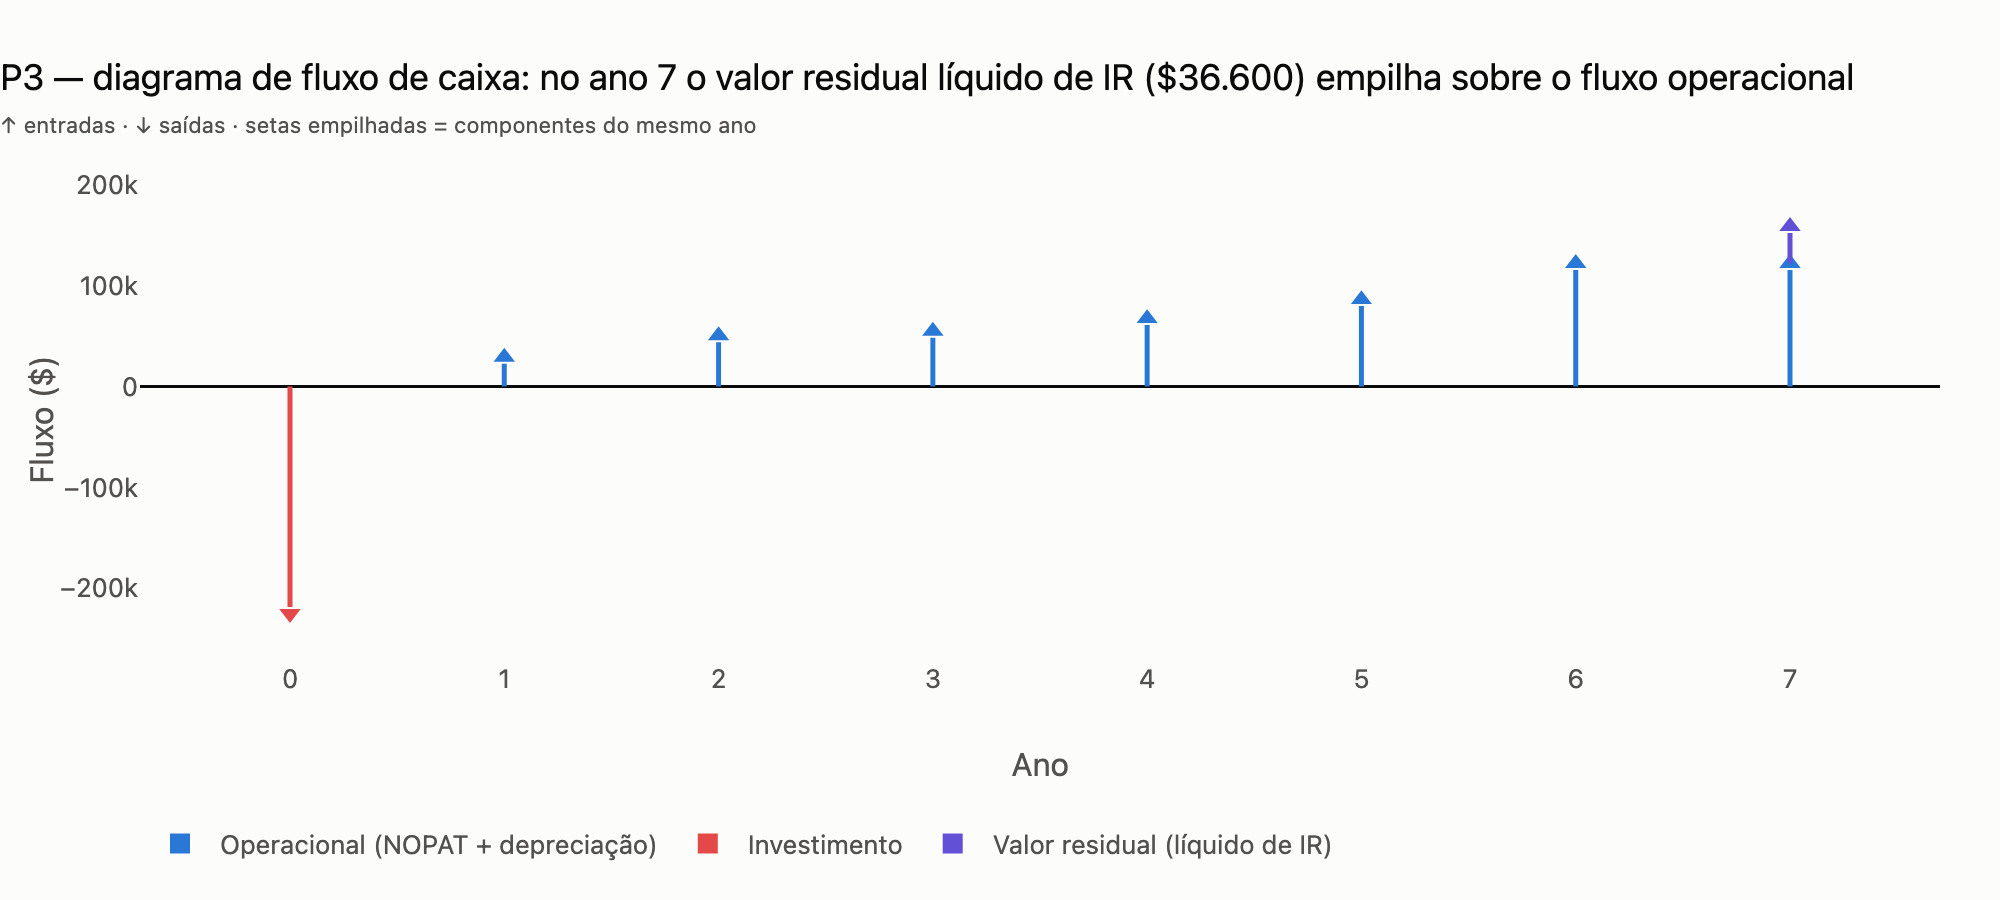

In [5]:
fig = viz.grafico_fluxo(p3, titulo="P3 — diagrama de fluxo de caixa: no ano 7 o valor residual líquido de IR ($36.600) empilha sobre o fluxo operacional")
viz.exportar(fig, f"{SAIDA}/diagrama_p3")
fig

In [6]:
unidades = Variacoes(30_000, {2: -0.02, 3: -0.02, 4: -0.03})
preco = Variacoes(20.0, {4: -0.05, 6: -0.04})
p4 = Projeto(
    "P4", vida_util=6, investimento=300_000,
    receitas=Produto(unidades, preco),
    custos={"Custo fixo": 200_000, "Custo variável": Produto(unidades, 9.0)},
    valor_residual=ValorResidual.perpetuidade(K),         # instalação: VR = NOPAT do ano 6 ÷ K
    aliquota_ir=IR,
)
estilizar_demonstrativo(p4.demonstrativo(), "P4 — substituição de equipamentos obsoletos")

ano,0,1,2,3,4,5,6
P4,,,,,,,
Receitas,–,$ 600.000,$ 588.000,$ 576.240,$ 531.005,$ 531.005,$ 509.765
Custo · Custo fixo,–,$ 200.000,$ 200.000,$ 200.000,$ 200.000,$ 200.000,$ 200.000
Custo · Custo variável,–,$ 270.000,$ 264.600,$ 259.308,$ 251.529,$ 251.529,$ 251.529
(−) Custos e despesas,–,$ 470.000,$ 464.600,$ 459.308,$ 451.529,$ 451.529,$ 451.529
(=) EBITDA,–,$ 130.000,$ 123.400,$ 116.932,$ 79.476,$ 79.476,$ 58.236
(−) Depreciação,–,$ 50.000,$ 50.000,$ 50.000,$ 50.000,$ 50.000,$ 50.000
(=) Lucro operacional (EBIT),–,$ 80.000,$ 73.400,$ 66.932,$ 29.476,$ 29.476,$ 8.236
(−) IR,–,$ 16.000,$ 14.680,$ 13.386,$ 5.895,$ 5.895,$ 1.647
(=) NOPAT,–,$ 64.000,$ 58.720,$ 53.546,$ 23.581,$ 23.581,$ 6.589


**Premissas de interpretação** (as mesmas da resolução de referência):

* P3: o crescimento de 10% "nos próximos 5 anos" aplica-se aos anos 2–6; o ano 7 repete o ano 6. O valor
  residual de mercado é tributado sobre o ganho em relação ao valor contábil (225.000 − 7 × 30.000 = 15.000):
  VR líquido = 42.000 − 20% × 27.000 = **36.600**.
* P4: "conceito de perpetuidade" → VR = NOPAT₆ ÷ 18% = **36.605** (série perpétua do NOPAT, como nas notas).
* Prejuízo operacional (P3, ano 1) gera benefício fiscal imediato — a empresa é lucrativa.

## 2. Fluxos de caixa globais

In [7]:
projetos = [p1, p2, p3, p4]
estilizar(tabela_fluxos(projetos, transpor=True), tipos={c: "moeda" for c in range(8)}, destacar=[], titulo="FCG por projeto ($)")

ano,0,1,2,3,4,5,6,7
P1,($ 200.000),$ 70.000,$ 70.000,$ 70.000,$ 70.000,$ 70.000,$ 0,$ 0
P2,($ 200.000),$ 90.000,$ 85.000,$ 75.000,$ 50.000,$ 50.000,$ 0,$ 0
P3,($ 225.000),$ 29.040,$ 50.352,$ 54.787,$ 67.332,$ 86.116,$ 121.957,$ 158.557
P4,($ 300.000),$ 114.000,$ 108.720,$ 103.546,$ 73.581,$ 73.581,$ 93.194,$ 0


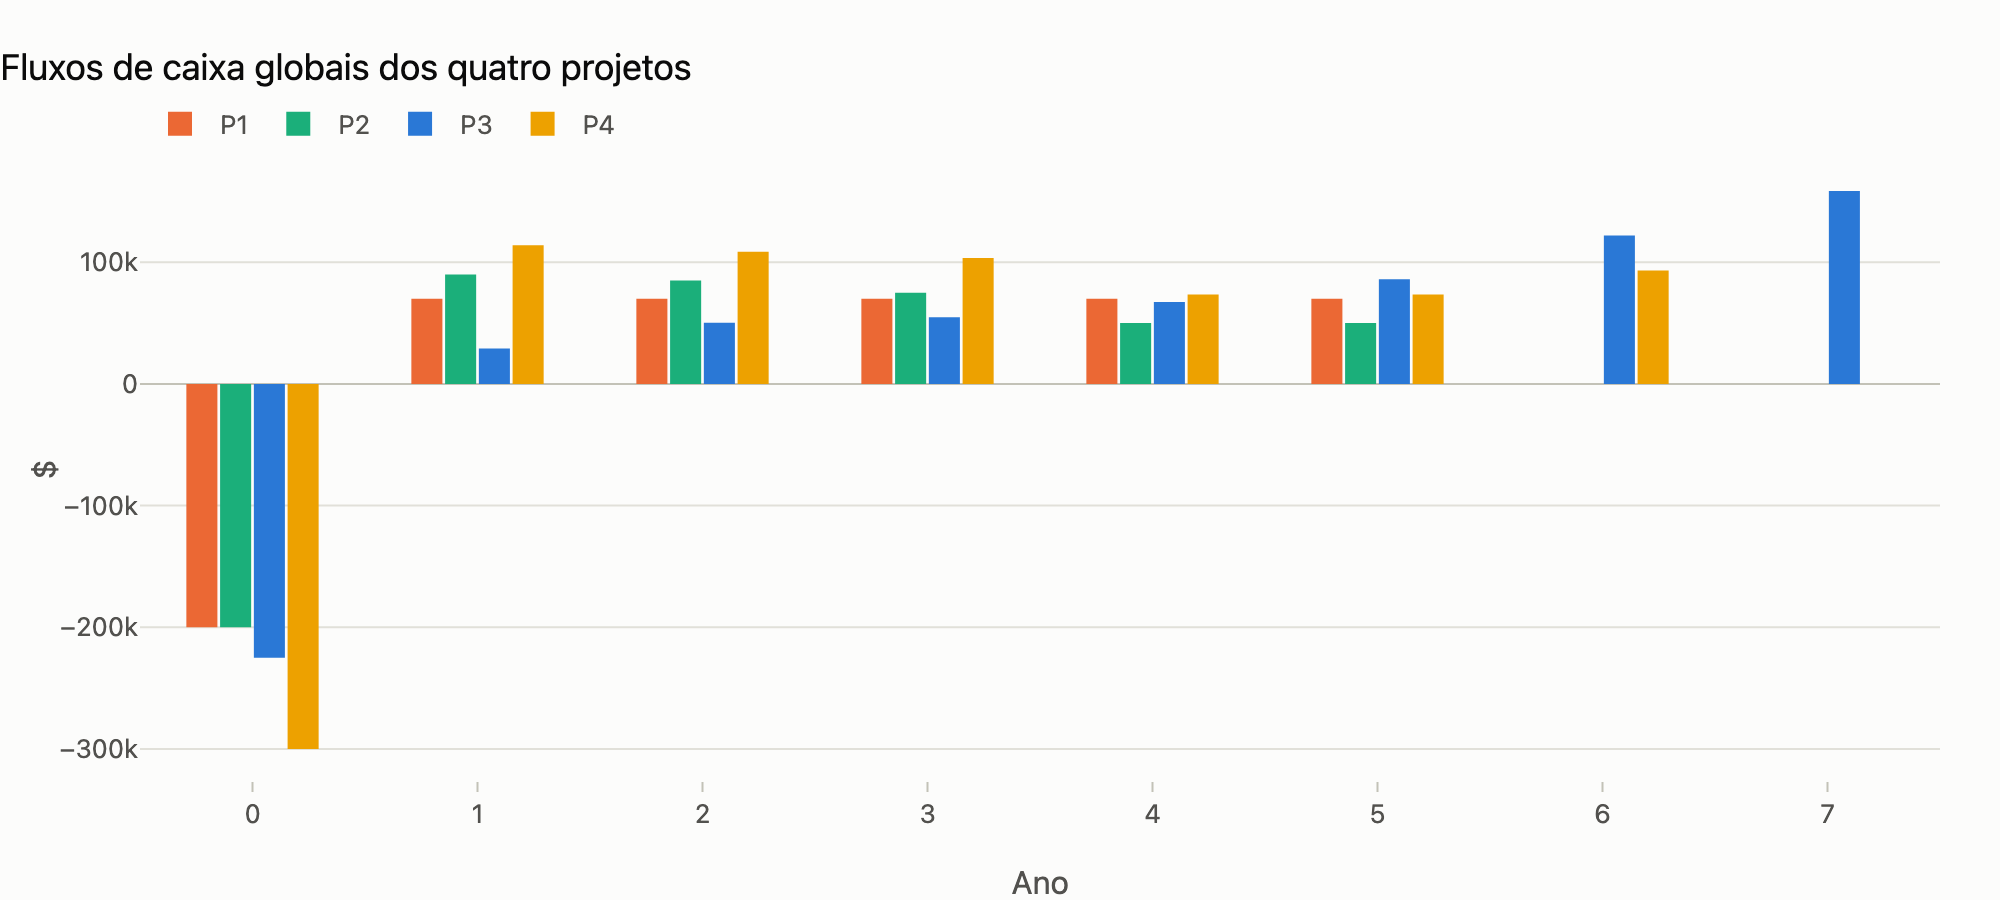

In [8]:
fig = viz.grafico_fluxos(projetos, titulo="Fluxos de caixa globais dos quatro projetos")
viz.exportar(fig, f"{SAIDA}/fluxos")
fig

## 3. Todos os métodos de avaliação

`tabela_indicadores` calcula VPL, TIR, TIRM (reinvestimento à TMA), RAU, IBC, ROIA e os dois paybacks.
`ranking` acrescenta a posição de cada projeto em cada critério.

In [9]:
tab = tabela_indicadores(projetos, K)
estilizar(tab, titulo="Indicadores a 18% a.a. (★ = melhor em cada critério)")

,Investimento,Vida (anos),VPL,TIR,TIRM,RAU,IBC,ROIA,Payback simples,Payback ajustado
Projeto,,,,,,,,,,
P1,$ 200.000,5,$ 18.902,"22,11%","20,15%",$ 6.044,"1,09","1,82%","2,86 anos","4,38 anos"
P2,$ 200.000,5,$ 30.609,"25,46%","21,41%",$ 9.788,"1,15","2,89%","2,33 anos","3,66 anos"
P3,$ 225.000,7,$ 36.440,"22,19%","20,56%",$ 9.561,"1,16","2,17%","4,27 anos","6,27 anos"
P4,$ 300.000,6,$ 42.350,"23,82%","20,63%",$ 12.108,"1,14","2,23%","2,75 anos","4,76 anos"


In [10]:
rk = ranking(projetos, K)[[c for c in ranking(projetos, K).columns if c.startswith("rank_")]]
rk.columns = [c.replace("rank_", "") for c in rk.columns]
estilizar_gradiente(rk, vmin=1, vmax=4, inverter=True, formato="{:.0f}", titulo="Posição em cada critério (1 = melhor)")

,vpl,tir,tirm,rau,ibc,roia,payback,payback_descontado
Projeto,,,,,,,,
P1,4,4,4,4,4,4,3,2
P2,3,1,1,2,2,1,1,1
P3,2,3,3,3,1,3,4,4
P4,1,2,2,1,3,2,2,3


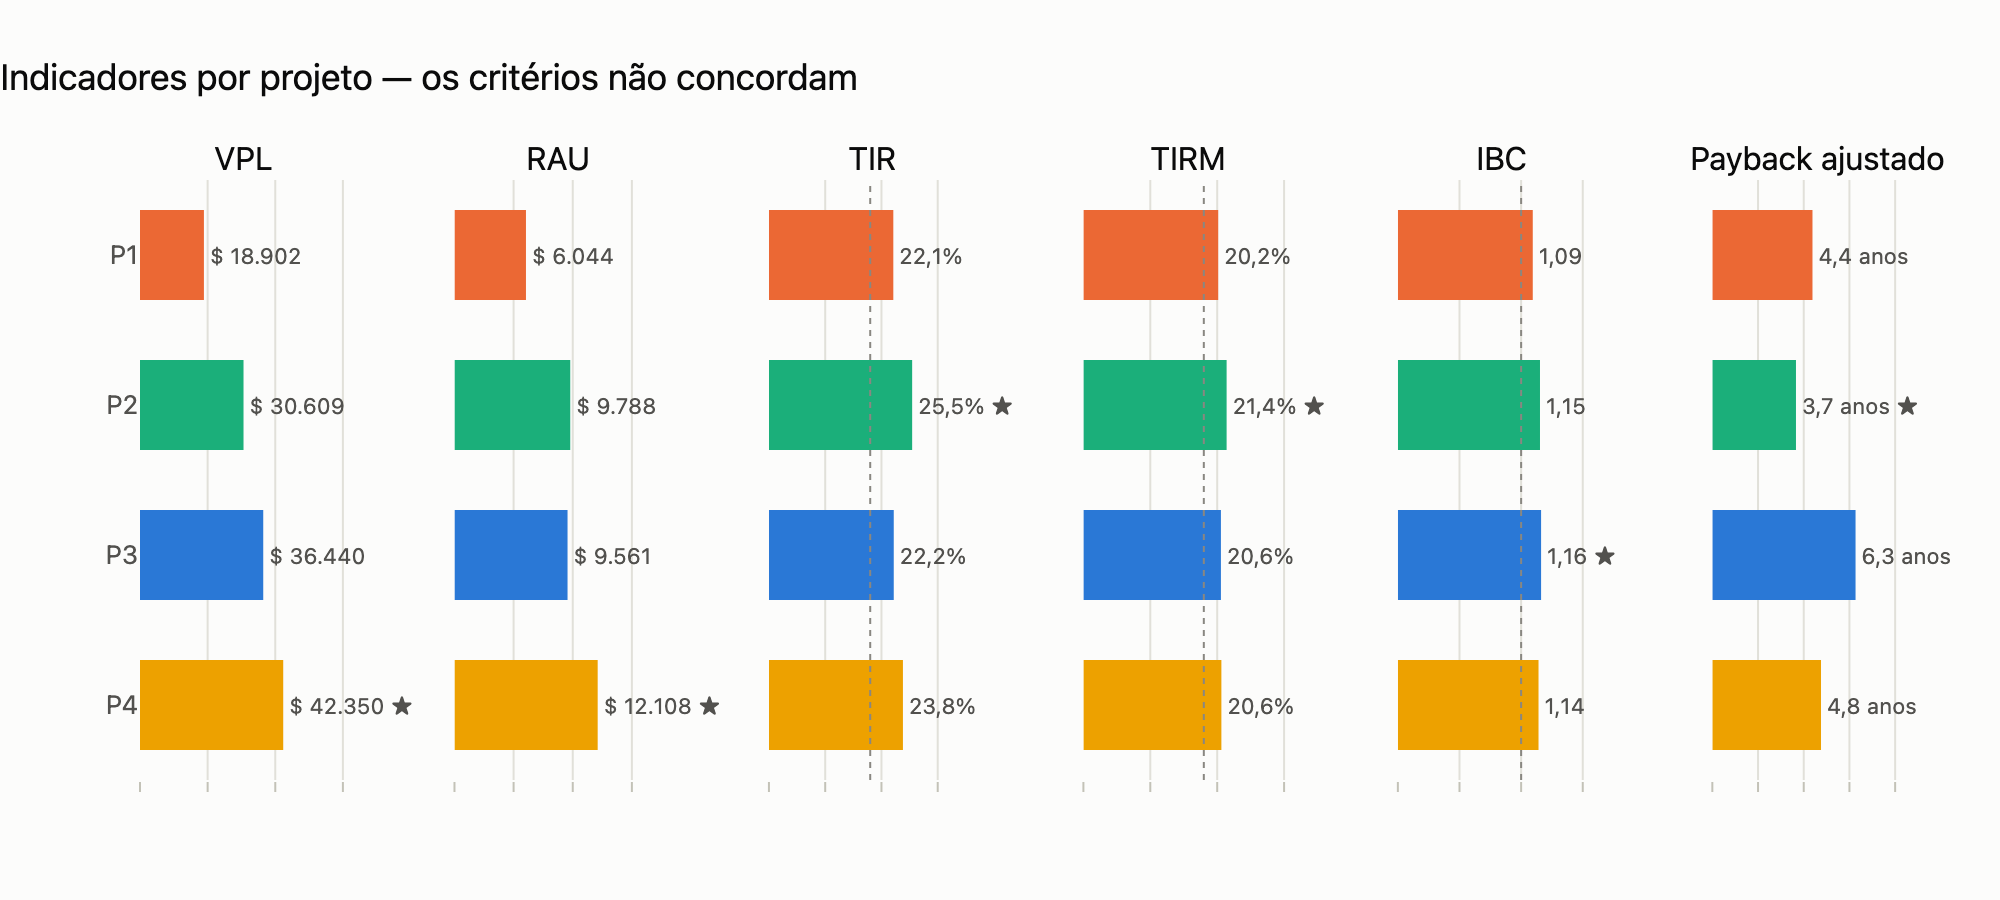

In [11]:
fig = viz.grafico_painel_indicadores(tab, colunas=["vpl", "rau", "tir", "tirm", "ibc", "payback_descontado"], referencias={"tir": K, "tirm": K, "ibc": 1.0},
                                     titulo="Indicadores por projeto — os critérios não concordam")
viz.exportar(fig, f"{SAIDA}/painel_indicadores")
fig

**Leitura.** Todos os projetos são viáveis (VPL > 0, TIR > 18%, IBC > 1). Mas os critérios divergem:

* **VPL**: P4 > P3 > P2 > P1 — mede riqueza criada, mas em horizontes diferentes (5, 6 e 7 anos);
* **RAU**: P4 > **P2 > P3** > P1 — anualizando, P2 (5 anos) supera P3 (7 anos): o VPL de P3 é maior porque
  o projeto é mais longo, não porque é mais rentável por ano;
* **TIR / TIRM / payback**: P2 lidera — recupera o capital mais rápido, mas é pequeno; a TIRM comprime todas as
  taxas para 20–21% (hipótese realista de reinvestimento a 18%);
* **IBC**: P3 lidera — mais valor por $ investido.

Vidas diferentes e escalas diferentes são exatamente os casos em que a comparação direta engana. Daí a
análise marginal.

## 4. Vidas úteis diferentes: empilhar até o horizonte comum

Para comparar P2 (5 anos) com P3 (7 anos) empilhamos ciclos até o MMC (35 anos). O fluxo marginal P3 − P2
tem TIR de 17,8% < 18% e VPL marginal negativo: **P2 é preferível a P3** sob a hipótese de repetição — o
contrário do que o VPL simples sugere, e o mesmo que o RAU diz.

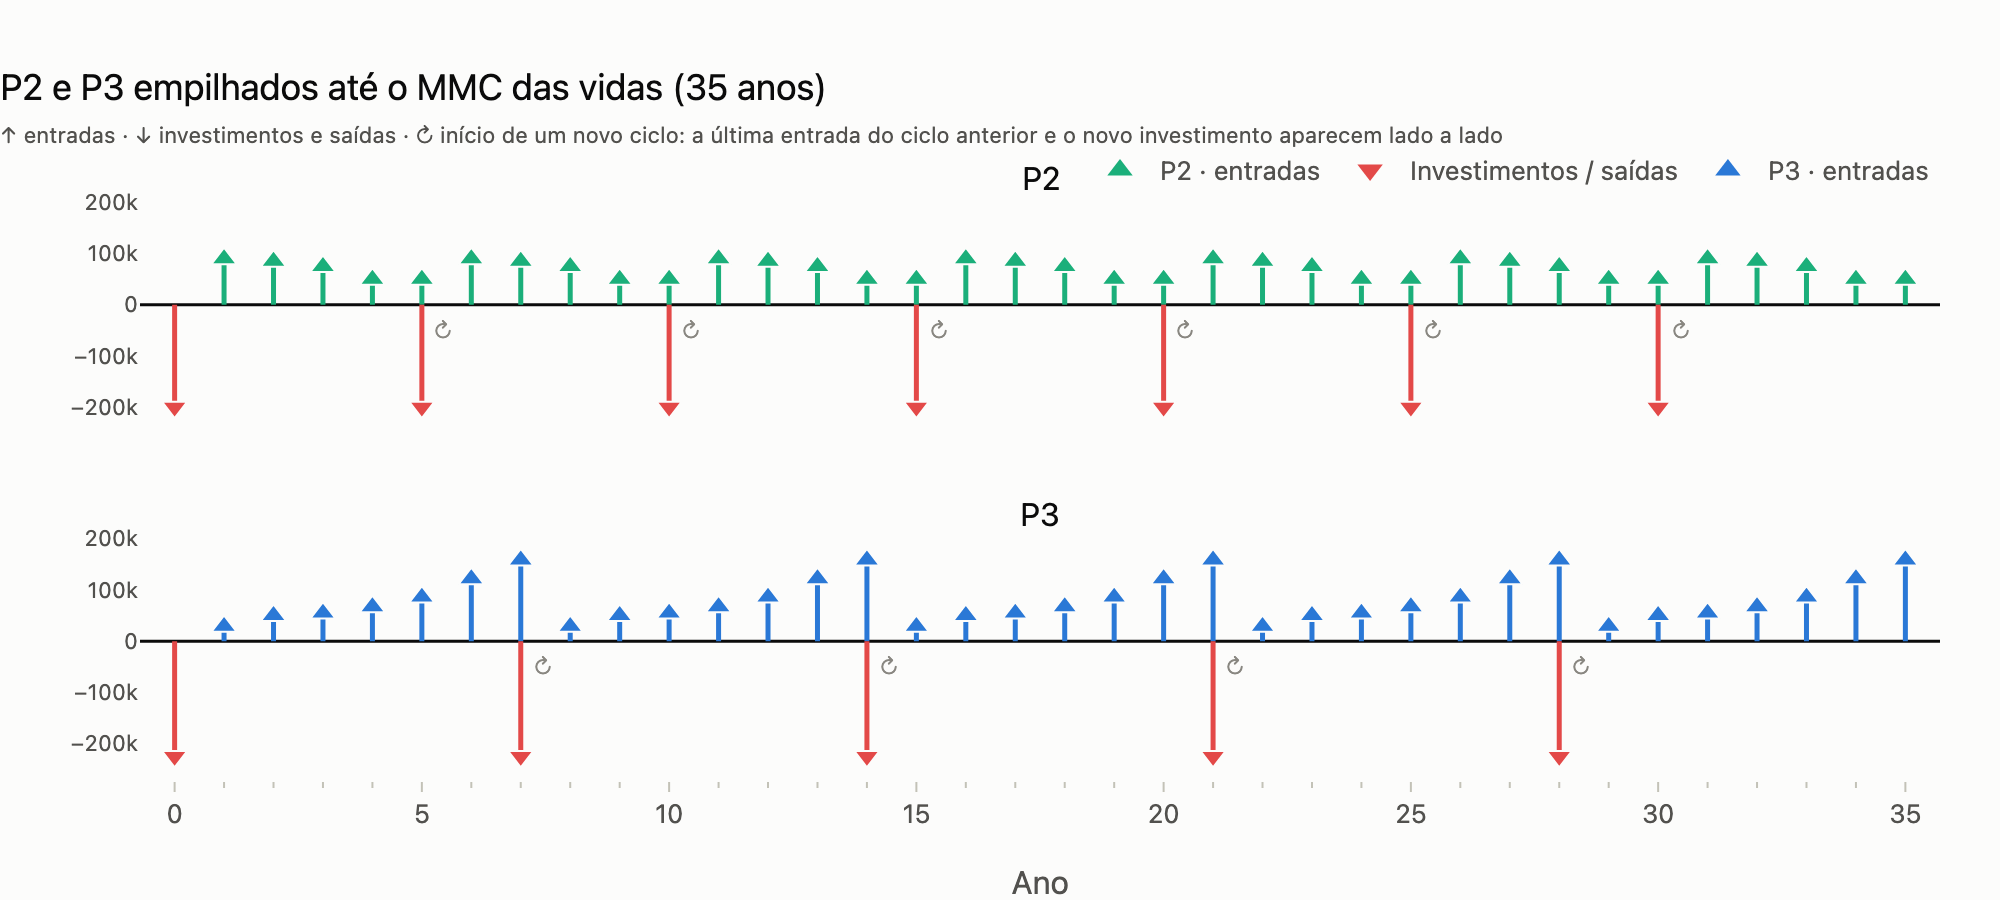

In [12]:
fig = viz.grafico_fluxos_empilhados([p2, p3], metodo="mmc", titulo="P2 e P3 empilhados até o MMC das vidas (35 anos)")
viz.exportar(fig, f"{SAIDA}/empilhados_p2_p3")
fig

In [13]:
m23 = fluxo_marginal(p2, p3, metodo="mmc")
print(f"Horizonte comum: {m23.n} anos | investimento marginal: {m23.investimento_inicial:,.0f}")
print(f"TIR marginal (P3 − P2) = {tir(m23):.2%}   VPL marginal a 18% = {vpl(m23, K):,.0f}   RAU marginal = {rau(m23, K):,.0f}  (= RAU P3 − RAU P2 = {rau(p3, K) - rau(p2, K):,.0f})")

Horizonte comum: 35 anos | investimento marginal: 25,000
TIR marginal (P3 − P2) = 17.77%   VPL marginal a 18% = -1,261   RAU marginal = -228  (= RAU P3 − RAU P2 = -228)


`equalizar` oferece as três hipóteses de horizonte. O VPL sobre o MMC de todas as vidas (210 anos) ordena os
projetos **exatamente como o RAU** — por isso, na prática, basta o RAU:

In [14]:
comparativo = pd.DataFrame({
    "VPL (vida própria)": {p.nome: vpl(p, K) for p in projetos},
    "RAU": {p.nome: rau(p, K) for p in projetos},
    "VPL empilhado até 210 anos": {f.nome: vpl(f, K) for f in equalizar(projetos, "mmc")},
    "VPL truncado em 5 anos (c/ valor econômico)": {f.nome: vpl(f, K) for f in equalizar(projetos, "truncar", taxa=K)},
})
estilizar(comparativo, tipos={c: "moeda" for c in comparativo.columns}, destacar=list(comparativo.columns), titulo="Três hipóteses de horizonte")

,VPL (vida própria),RAU,VPL empilhado até 210 anos,VPL truncado em 5 anos (c/ valor econômico)
P1,$ 18.902,$ 6.044,$ 33.580,$ 18.902
P2,$ 30.609,$ 9.788,$ 54.378,$ 30.609
P3,$ 36.440,$ 9.561,$ 53.114,$ 36.440
P4,$ 42.350,$ 12.108,$ 67.268,$ 42.350


## 5. Análise marginal entre **todos** os pares

Para cada par (defensor = menor investimento, desafiante = maior) calculamos o fluxo marginal no horizonte
comum e a sua TIR, VPL e RAU. O desafiante vence se o VPL marginal à TMA é positivo (equivalente a TIR
marginal > TMA quando o fluxo marginal é convencional).

In [15]:
am = analise_marginal(projetos, K, metodo="mmc")
estilizar(am.drop(columns=["TIRM marginal"]), tipos={"Horizonte": "int", "Nº de TIRs": "int"}, destacar=[], titulo="Análise marginal, todos os pares (horizonte = MMC das vidas)")

,Defensor,Desafiante,Horizonte,Investimento marginal,VPL marginal,TIR marginal,RAU marginal,Nº de TIRs,TIRs,Preferido
0,P1,P2,5,$ 0,$ 11.707,—,$ 3.744,1,mesmo investimento,P2
1,P1,P3,35,$ 25.000,$ 19.474,"22,34%",$ 3.516,1,22.3%,P3
2,P1,P4,30,$ 100.000,$ 33.453,"27,79%",$ 6.064,1,27.8%,P4
3,P2,P3,35,$ 25.000,($ 1.261),"17,77%",($ 228),1,17.8%,P2
4,P2,P4,30,$ 100.000,$ 12.799,"21,02%",$ 2.320,1,21.0%,P4
5,P3,P4,42,$ 75.000,$ 14.140,"9,94%",$ 2.548,2,"9.9%, 63.7%",P4


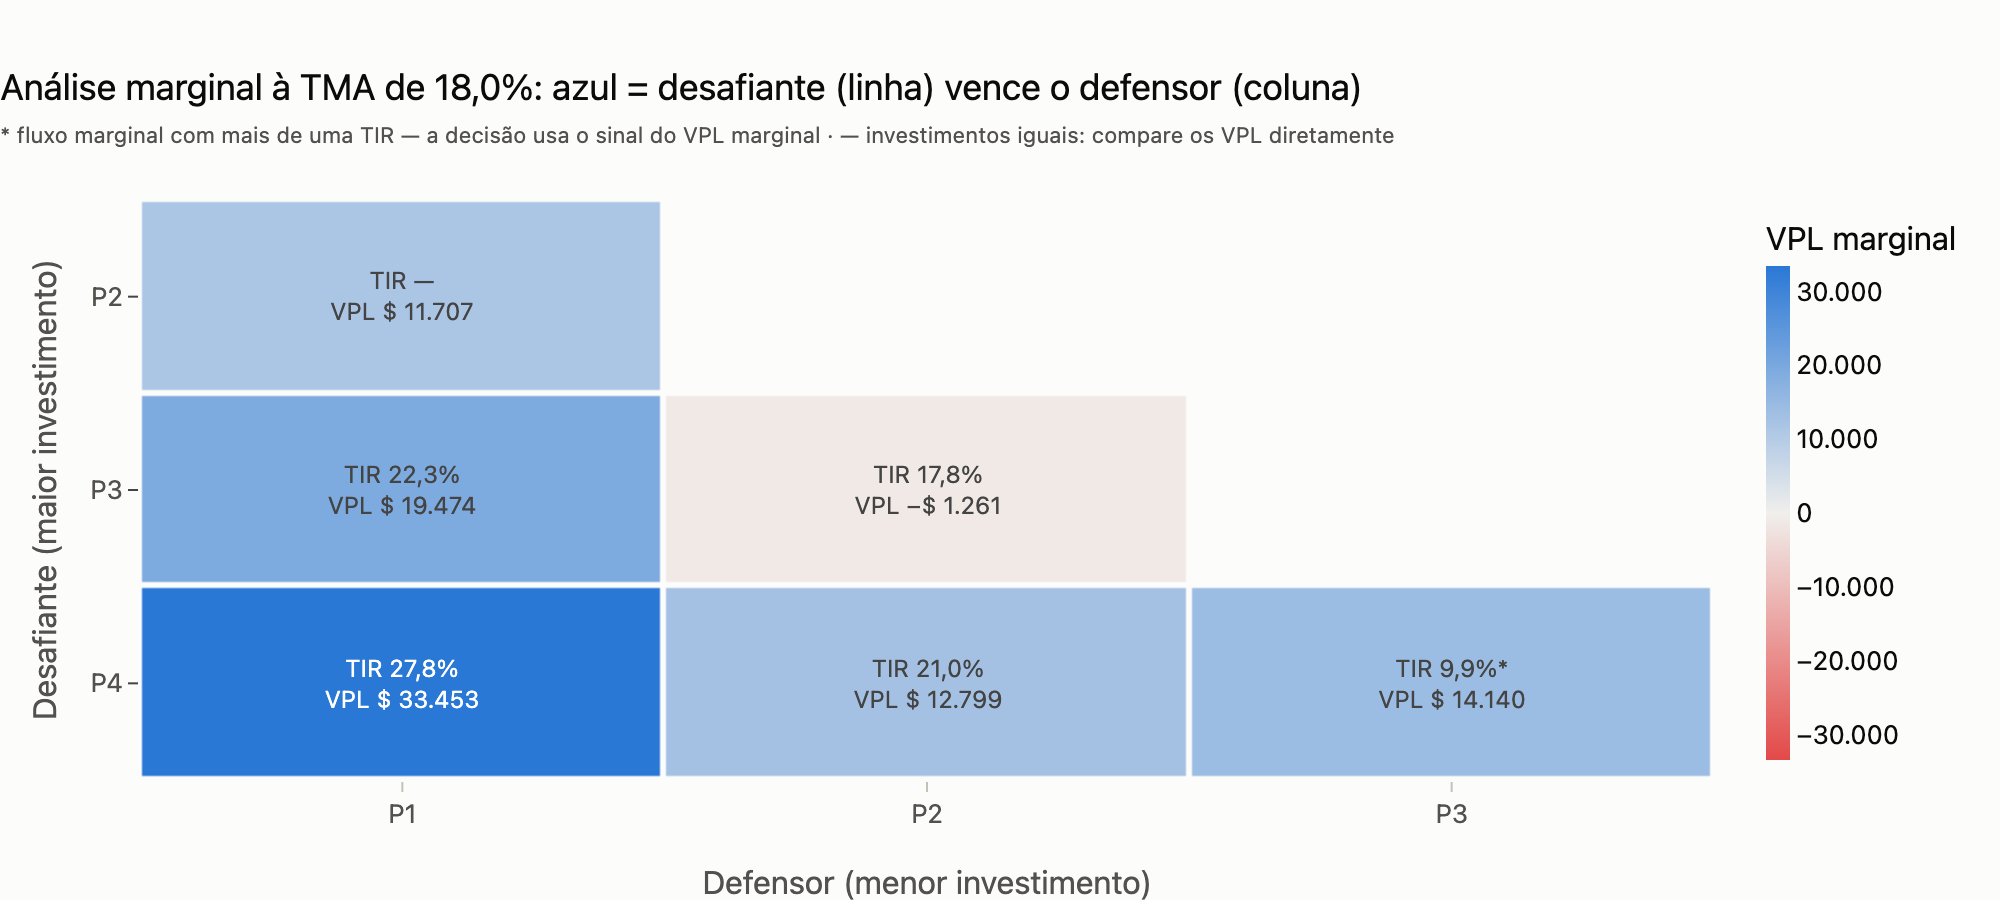

In [16]:
fig = viz.grafico_matriz_marginal(am, K)
viz.exportar(fig, f"{SAIDA}/matriz_marginal")
fig

Dois pares exigem cuidado — e mostram por que a biblioteca decide pelo **sinal do VPL marginal**:

* **P1 × P2** têm o mesmo investimento: o fluxo marginal não tem desembolso inicial, logo não existe "taxa de
  retorno do capital adicional". Compara-se o VPL diretamente: P2 vence por $11.707.
* **P3 × P4** (42 anos): o fluxo marginal muda de sinal várias vezes e tem **duas TIR** (9,9% e 63,7%). O VPL
  marginal só é positivo entre elas; como 18% está nesse intervalo, P4 vence. Uma leitura ingênua ("TIR marginal
  9,9% < 18%, rejeite o desafiante") erraria.

TIRs do fluxo marginal P4 − P3: ['9.9%', '63.7%']


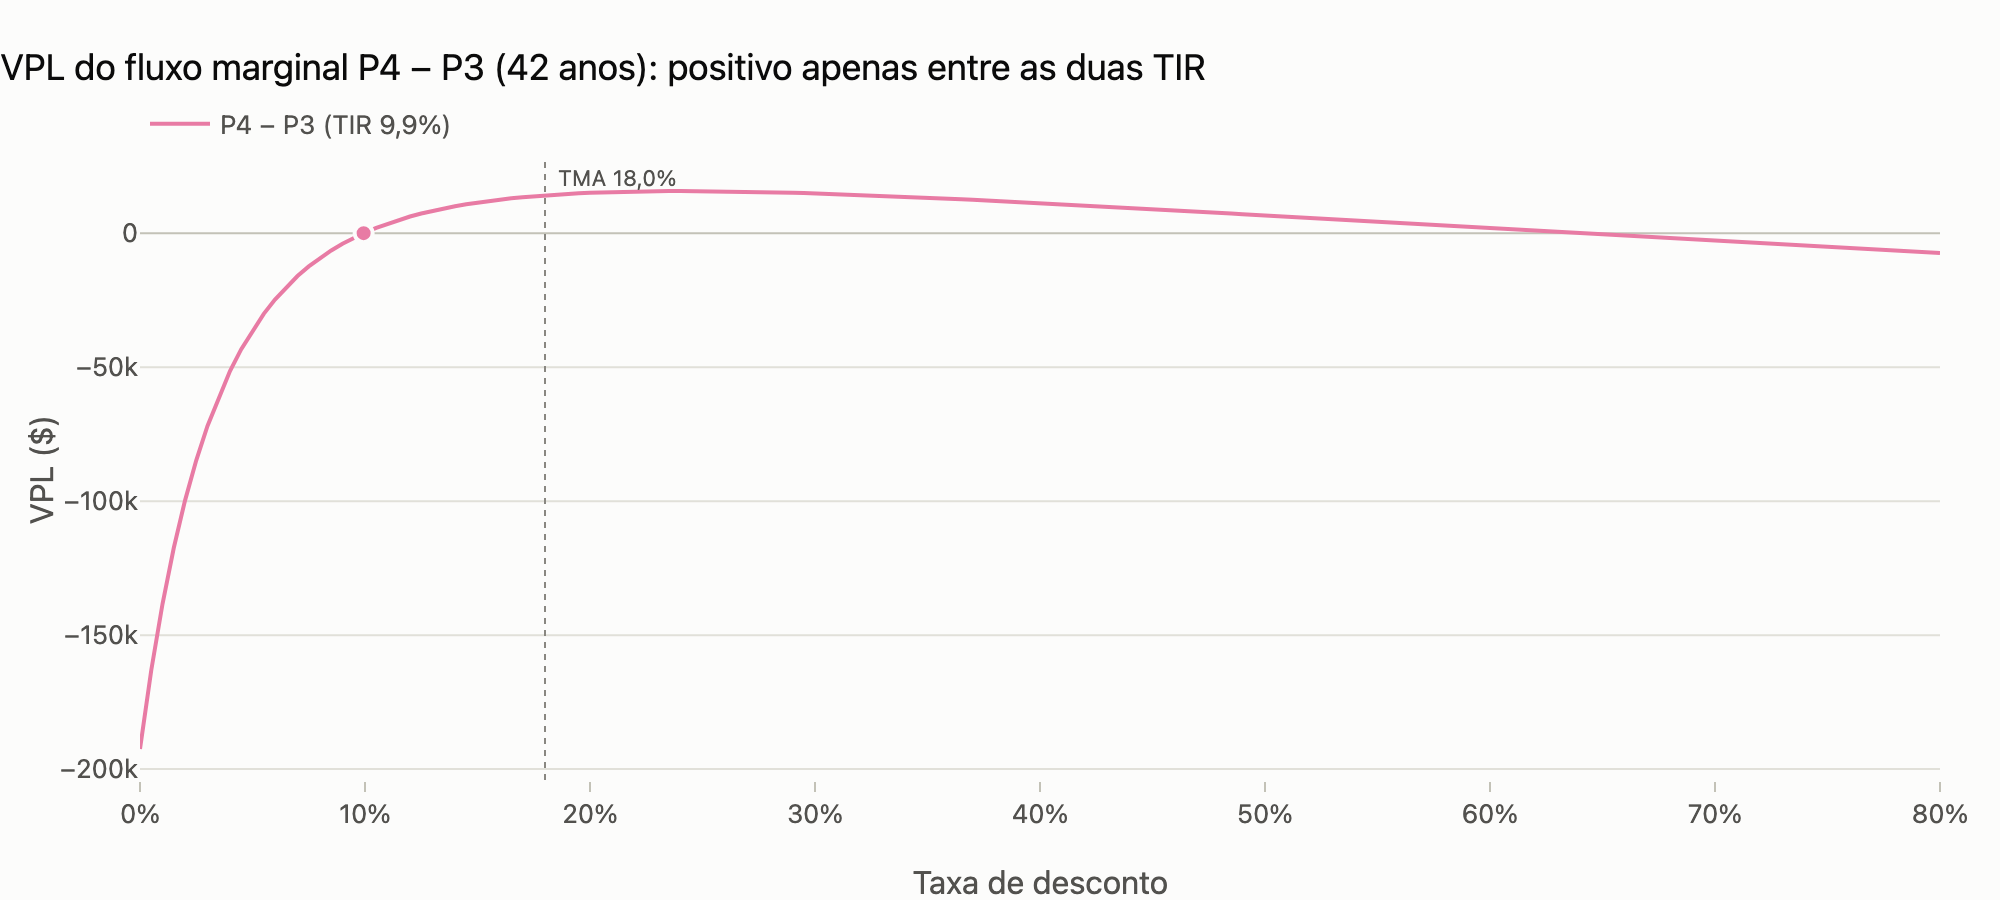

In [17]:
m34 = fluxo_marginal(p3, p4, metodo="mmc")
print("TIRs do fluxo marginal P4 − P3:", [f"{r:.1%}" for r in tir(m34, todas=True)])
fig = viz.grafico_perfil_vpl([m34], K, taxas=np.linspace(0, 0.8, 161), fisher=False, titulo="VPL do fluxo marginal P4 − P3 (42 anos): positivo apenas entre as duas TIR")
fig

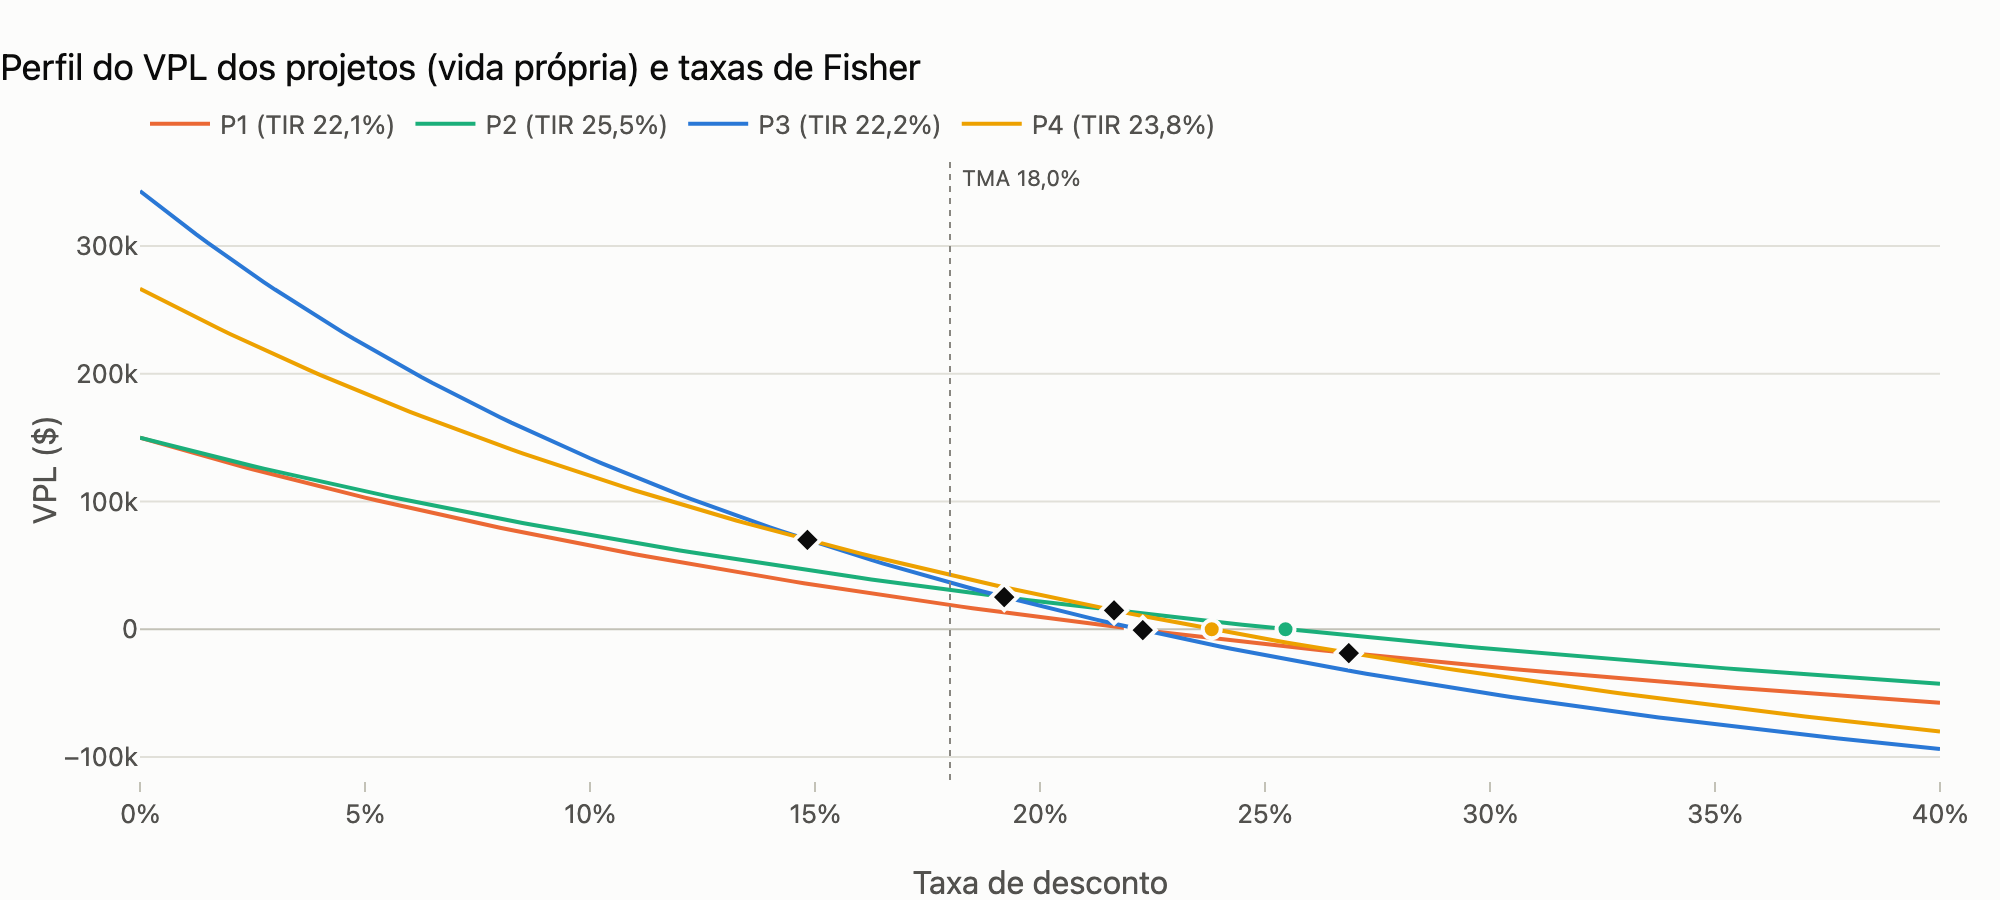

In [18]:
fig = viz.grafico_perfil_vpl(projetos, K, taxas=np.linspace(0, 0.40, 161), titulo="Perfil do VPL dos projetos (vida própria) e taxas de Fisher")
viz.exportar(fig, f"{SAIDA}/perfil_vpl")
fig

A **seleção incremental** (defensor × desafiante em sequência) chega ao mesmo campeão que o RAU:

In [19]:
campeao, trilha = campeao_incremental(projetos, K, metodo="mmc")
print("Campeão pela análise incremental:", campeao)
estilizar(trilha, tipos={"VPL marginal": "moeda", "TIR marginal": "pct"}, destacar=[], titulo="Trilha da análise incremental")

Campeão pela análise incremental: P4


,Defensor,Desafiante,VPL marginal,TIR marginal,Vence
0,—,P1,$ 18.902,"22,11%",P1
1,P1,P2,$ 11.707,"0,00%",P2
2,P2,P3,($ 1.261),"17,77%",P2
3,P2,P4,$ 12.799,"21,02%",P4


## 6. Carteiras: escolher dois projetos

Como os projetos são independentes, o VPL da carteira é a soma dos VPLs. Enumeramos as seis combinações de
dois projetos (`carteiras(k=2)`), com TIR e payback do fluxo agregado e a soma dos RAU.

In [20]:
cart, fluxos_cart = carteiras(projetos, K, k=2)
estilizar(cart.set_index("Carteira").drop(columns=["Horizonte"]), tipos={"Nº projetos": "int"}, titulo="Carteiras de dois projetos")

,Nº projetos,Investimento,VPL,RAU (soma),TIR,TIRM,IBC,Payback ajustado
Carteira,,,,,,,,
P3 + P4,2,$ 525.000,$ 78.790,$ 21.669,"22,94%","20,38%","1,15","5,64 anos"
P2 + P4,2,$ 500.000,$ 72.959,$ 21.896,"24,41%","20,71%","1,15","4,29 anos"
P2 + P3,2,$ 425.000,$ 67.049,$ 19.349,"23,27%","20,50%","1,16","5,62 anos"
P1 + P4,2,$ 500.000,$ 61.252,$ 18.153,"23,15%","20,29%","1,12","4,57 anos"
P1 + P3,2,$ 425.000,$ 55.342,$ 15.605,"22,16%","20,08%","1,13","5,88 anos"
P1 + P2,2,$ 400.000,$ 49.511,$ 15.833,"23,69%","20,79%","1,12","4,06 anos"


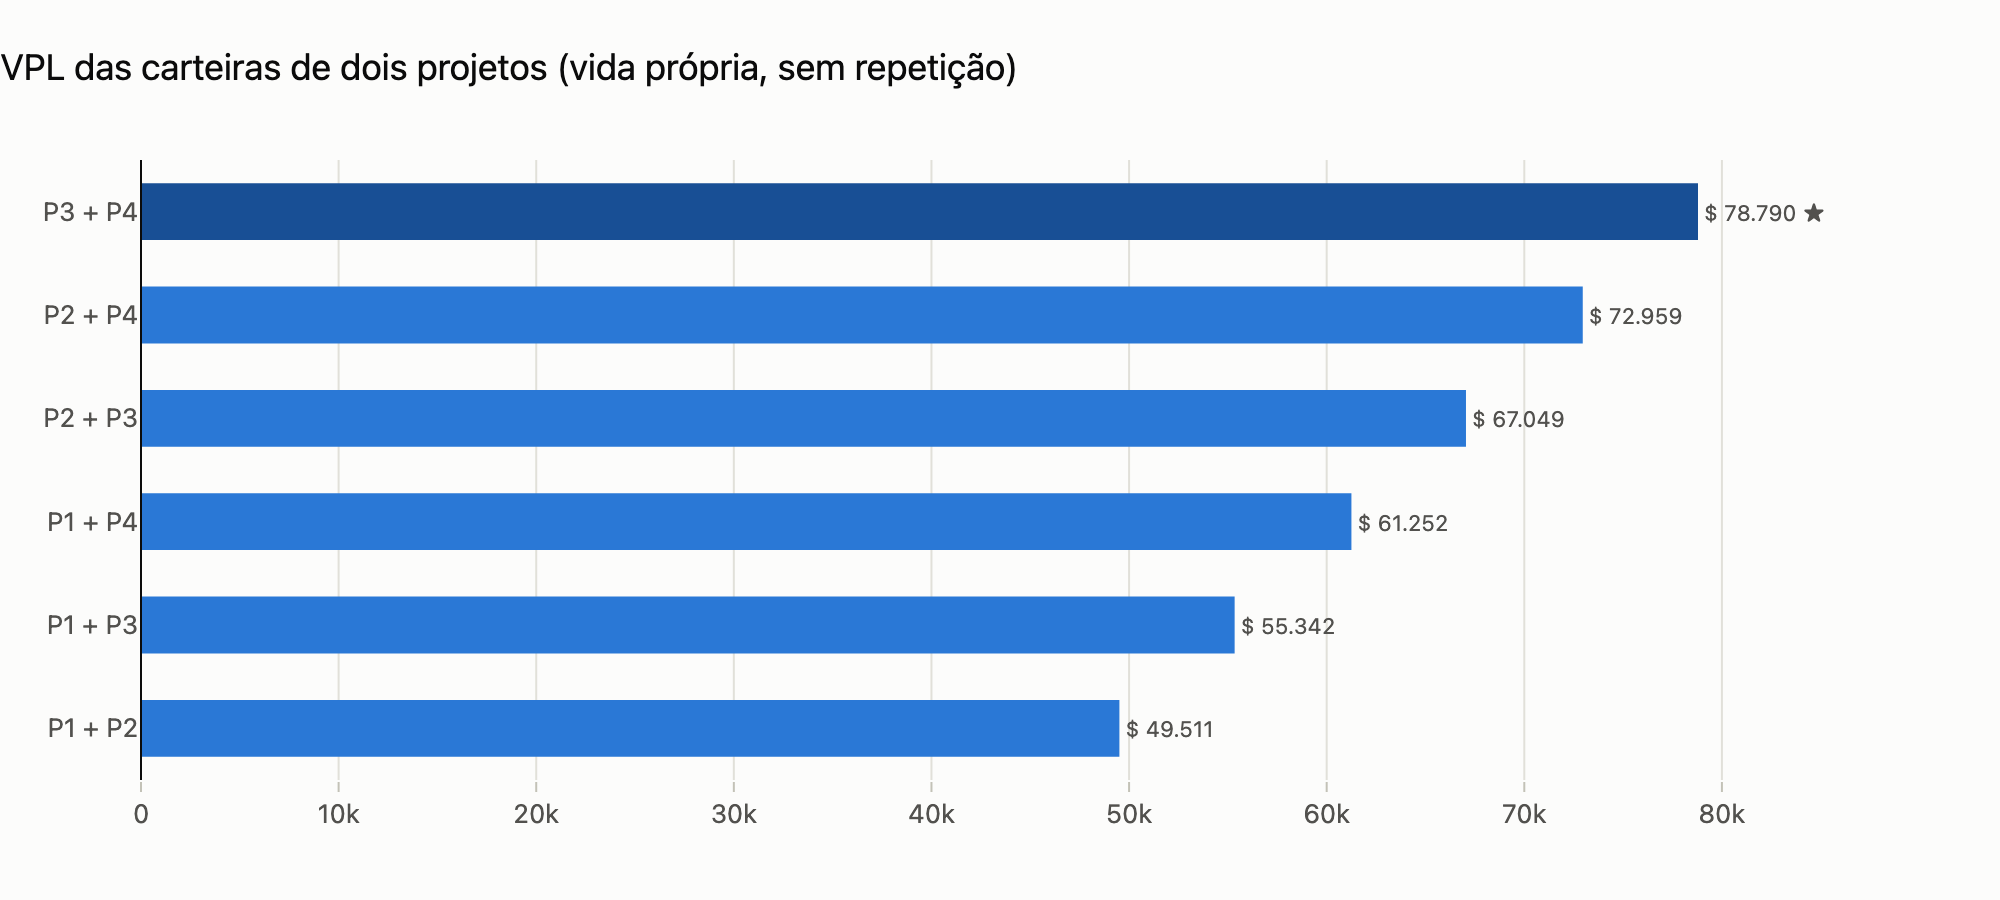

In [21]:
fig = viz.grafico_carteiras(cart.set_index("Carteira"), coluna="VPL", faixa=None, titulo="VPL das carteiras de dois projetos (vida própria, sem repetição)")
viz.exportar(fig, f"{SAIDA}/carteiras_vpl")
fig

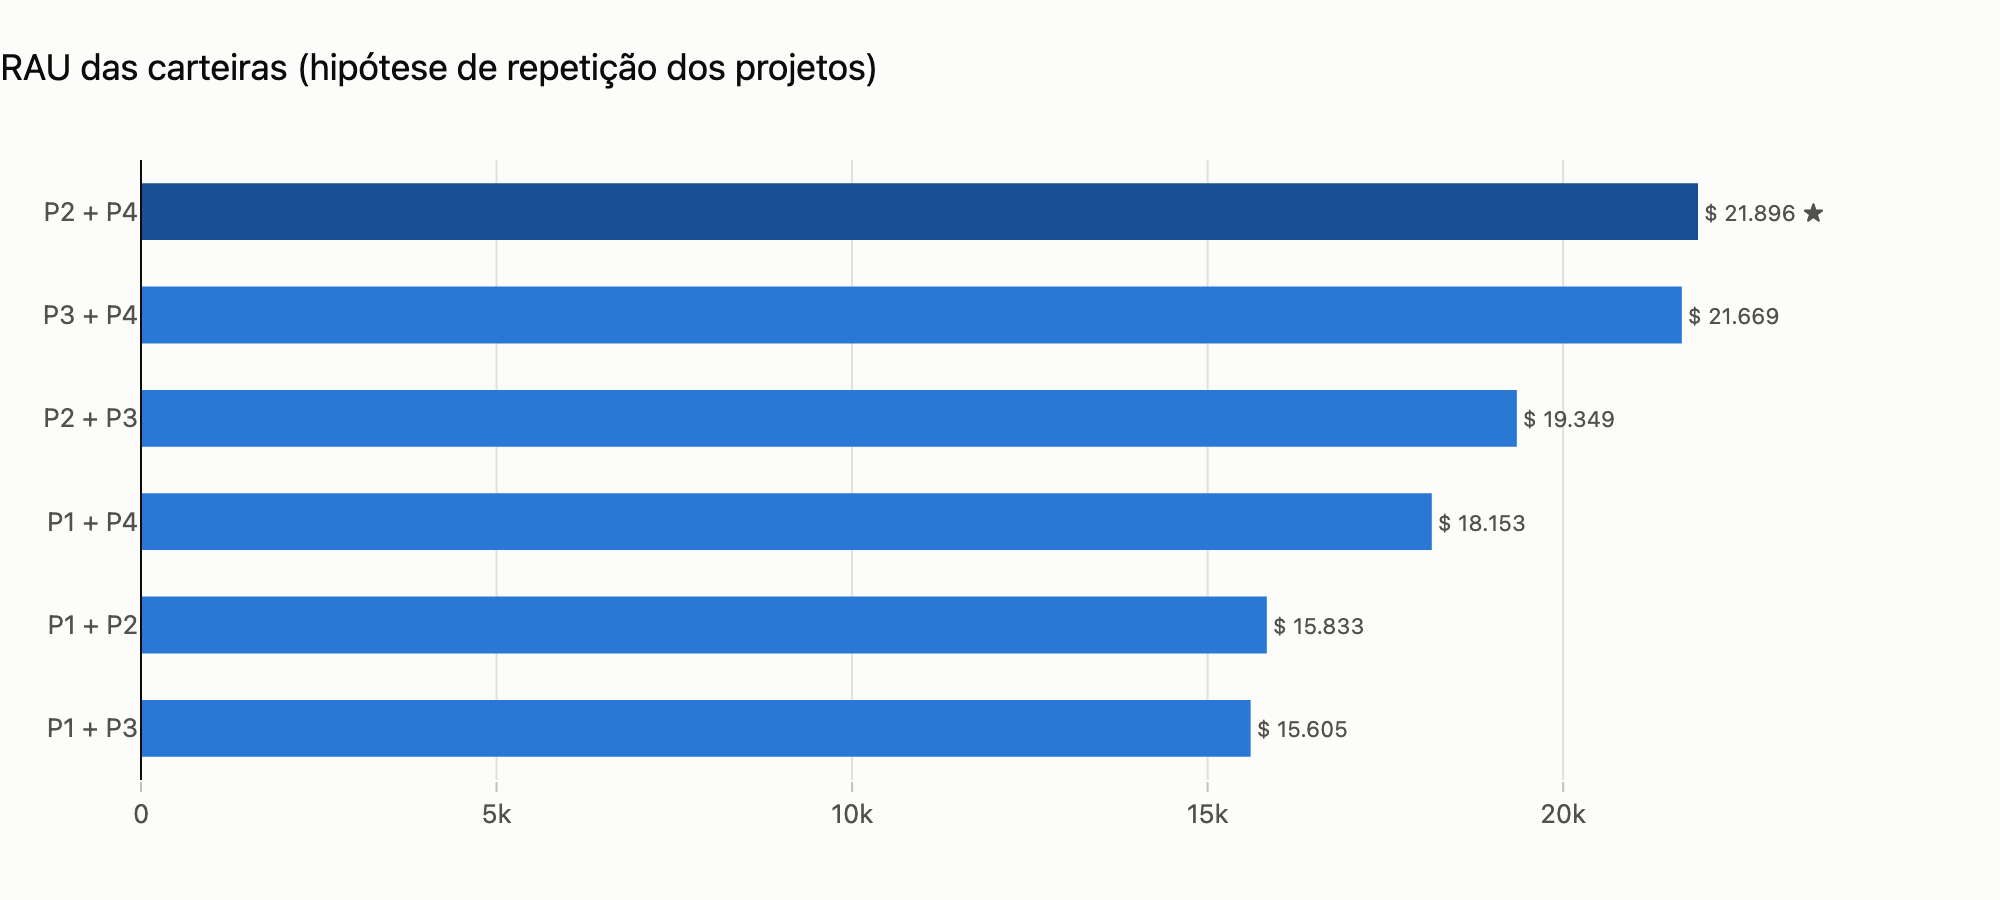

In [22]:
fig = viz.grafico_carteiras(cart.set_index("Carteira").sort_values("RAU (soma)", ascending=False), coluna="RAU (soma)", faixa=None,
                            titulo="RAU das carteiras (hipótese de repetição dos projetos)")
viz.exportar(fig, f"{SAIDA}/carteiras_rau")
fig

## 7. Parecer (caso-base)

| Pergunta | Resposta | Critério |
|---|---|---|
| Melhor projeto isolado | **P4** | maior VPL, maior RAU e vencedor de todas as comparações marginais |
| Dois melhores (sem repetição dos projetos) | **P4 + P3** | maior VPL da carteira ($78.790) |
| Dois melhores (com repetição / comparação anualizada) | **P4 + P2** | maior soma de RAU ($21.896); P2 vence P3 na análise marginal a 35 anos |

A escolha entre P3 e P2 como segundo projeto depende da hipótese sobre o que acontece ao fim das vidas
úteis — uma decisão de negócio, não de cálculo. Em ambos os casos a diferença é pequena (~$5.800 de VPL ou
~$230/ano de RAU), e o que realmente separa os projetos é o **risco**: P4 tem custo fixo de $200.000/ano e
margens estreitas, P3 depende de crescimento de 10% a.a. durante cinco anos. É o tema dos próximos notebooks.